# Problem 4

A man speaks the truth 2 out of 3 times. He throws one die and says that number obtained is a three. Find the probability that the number obtained is actually a three.



The challenge in this problem is that there are three classes hidden in the description:

1. the roll of the die
1. his decision to lie or tell the truth
1. what he says ( most importantly, when he lies )

It's that third class that is the least obvious and, in fact, left to the use to determine its events.

## Using Python with Synthetic Data

In [ ]:
# Import needed modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fractions import Fraction


### Create synthetic data


Let's simulate a large number of rolls of the die.

In [ ]:
# create array of die rolls
n = 900_000
die_rolls = np.random.randint(1,7, n)
die_rolls[:18]


array([6, 3, 3, 2, 5, 1, 3, 3, 5, 5, 4, 1, 5, 6, 2, 5, 6, 6])

In [ ]:
np.unique(die_rolls, return_counts=True)

(array([1, 2, 3, 4, 5, 6]),
 array([150142, 150259, 150102, 149918, 150063, 149516]))

In [ ]:
# Count frequency of each facet - version 1
list( zip( *( np.unique(die_rolls, return_counts=True) ) ) )

[(np.int64(1), np.int64(150142)),
 (np.int64(2), np.int64(150259)),
 (np.int64(3), np.int64(150102)),
 (np.int64(4), np.int64(149918)),
 (np.int64(5), np.int64(150063)),
 (np.int64(6), np.int64(149516))]

In [ ]:
# Count frequency of each facet - version 2
np.column_stack(np.unique(die_rolls, return_counts=True))


array([[     1, 150142],
       [     2, 150259],
       [     3, 150102],
       [     4, 149918],
       [     5, 150063],
       [     6, 149516]])

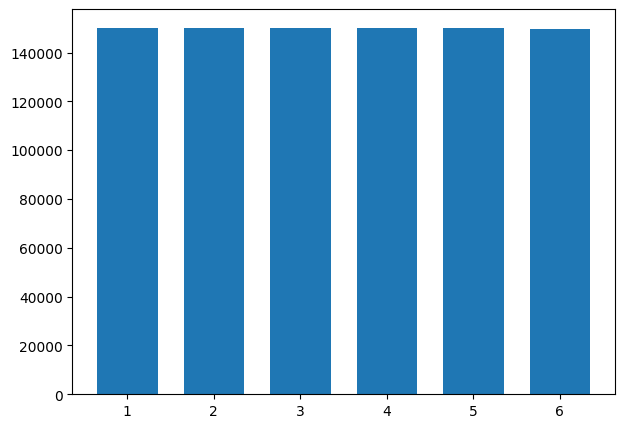

In [ ]:
# Generate histogram
plt.figure(figsize = (7,5))
plt.hist(die_rolls, bins=range(1,8), rwidth = 0.7, align = "left"  ) ;


### Part 1 - any lie


In [ ]:
a = np.array([ 1, 2, 3, 4, 5, 6 ] )
b = a[3:]
b[0] = 10
( a, b, b[0] )


(array([ 1,  2,  3, 10,  5,  6]), array([10,  5,  6]), np.int64(10))

In [ ]:
# Create list of answers corresponding to die rolls
# i.e. 2/3rds match die roll ( truth ), 1/3rd do not ( lies )
# also, lie can be any value other than the value of the roll
# e.g. if roll is 3, lie can be anything from { 1, 2, 4, 5, 6 }
facets = set(range(1, 7))       # number of facets on a die
answers = die_rolls.copy()      # create a copy of the randome die roll
lie_start = len(answers)*2//3   # calculate offset where to start lying
truth = answers[:lie_start]     # truthful answers ( first 2/3rds)
lies = answers[lie_start:]      # lies ( last 1/3rd)

# change answers to lies
for i, x in enumerate(lies) :
  choices = list(facets - {x})            # facets except the truth
  lies[i] = np.random.choice(choices)  # pick a false facet

# display truthful answers and lies
( len(answers), die_rolls[lie_start-5:lie_start+10], answers[lie_start-5:lie_start+10] )


(900000,
 array([2, 3, 1, 1, 2, 6, 3, 1, 4, 3, 1, 2, 5, 1, 2]),
 array([2, 3, 1, 1, 2, 2, 1, 4, 3, 1, 6, 5, 1, 6, 3]))

In [ ]:
# Create a data fram combining die rolls and answers
df = pd.DataFrame( { "Die": die_rolls,
                    "Answers": answers } )


#### Query the data

In [ ]:
# Filter for answers == 3 and die == 3
df["answers_3"] = ( df["Answers"] == 3 )
df["die_3"] = ( df["Die"] == 3 )
df


,Die,Answers,answers_3,die_3
0,6,6,False,False
1,3,3,True,True
2,3,3,True,True
3,2,2,False,False
4,5,5,False,False
...,...,...,...,...
899995,5,3,True,False
899996,6,2,False,False
899997,2,4,False,False
899998,5,2,False,False


In [ ]:
# Count each group
## |B| - count of answers
answer_is_3 = df["answers_3"].sum()

## |A| - count of die rols
die_is_3 = df["die_3"].sum()

## |A,B| = count of when the die is 3 and so is the answer
both_d = ( ( df["die_3"] == True ) & ( df["answers_3"] == True) ).sum()

## |B,A| = count of when the answer is 3 and so is the die
both_a = ( (df["answers_3"] == True ) & ( df["die_3"] == True)).sum()

( answer_is_3, die_is_3, both_a, both_d )


(np.int64(149765), np.int64(150102), np.int64(99902), np.int64(99902))

#### Directly query for P(A|B)

P(A,B) is when both the die and the answer are 3.
P(B) is when the die is 3.

Since ...

$ P(A,B) = \frac{|A,B|}{n} \quad $ and $ \quad P(B) = \frac{|B|}{n} $

therefore ...

$ \quad P(A|B) = \frac{P(A,B)}{P(B)} = $
$ \frac{|A,B|}{n} \div \frac{|B|}{n} = $
$ \frac{|A,B|}{n} \times \frac{n}{|B|} = $
$ \frac{|A,B|}{|B|} $


In [ ]:
# When answer given is 3, what is proportion that is actually 3?
both_d / answer_is_3

np.float64(0.6670583914799854)

In [ ]:
# Estimate fraction
Fraction.from_float( both_d / answer_is_3 ).limit_denominator(10)


Fraction(2, 3)

In [ ]:
# Calculate decimal equivalent
2/3


0.6666666666666666

### Part 2 - only 3's

In [ ]:
# Create list of answers corresponding to die rolls
# i.e. 2/3rds match die roll ( truth ), 1/3rd do not ( lies )
# also, if roll is not a 3, then the lie is *always* 3
# if the roll is a 3, then lie is 4
lies_3 = die_rolls.copy()
lie_start = len(lies_3)*2//3
truth = lies_3[:lie_start]
lies = lies_3[lie_start:]

for i, x in enumerate(lies) :
  choice = 4 if x == 3 else 3
  lies[i] = choice

( len(lies_3),
  die_rolls[lie_start-5:lie_start+10],
  answers[lie_start-5:lie_start+10],
  lies_3[lie_start-5:lie_start+10]
 )


(900000,
 array([2, 3, 1, 1, 2, 6, 3, 1, 4, 3, 1, 2, 5, 1, 2]),
 array([2, 3, 1, 1, 2, 2, 1, 4, 3, 1, 6, 5, 1, 6, 3]),
 array([2, 3, 1, 1, 2, 3, 4, 3, 3, 4, 3, 3, 3, 3, 3]))

In [ ]:
# Lies are always == 3
df["lies_3"] = lies_3
df["lie_3_true"] = ( df["lies_3"] == 3 )
df


,Die,Answers,answers_3,die_3,lies_3,lie_3_true
0,6,6,False,False,6,False
1,3,3,True,True,3,True
2,3,3,True,True,3,True
3,2,2,False,False,2,False
4,5,5,False,False,5,False
...,...,...,...,...,...,...
899995,5,3,True,False,3,True
899996,6,2,False,False,3,True
899997,2,4,False,False,3,True
899998,5,2,False,False,3,True


#### Query the data

In [ ]:
# Count groups
lie_is_3 = df["lie_3_true"].sum()
both_l = (( df["die_3"] == True) & ( df["lie_3_true"] == True)).sum()
( answer_is_3, die_is_3, lie_is_3, both_d, both_a, both_l )


(np.int64(149765),
 np.int64(150102),
 np.int64(349702),
 np.int64(99902),
 np.int64(99902),
 np.int64(99902))

#### Directly query for P(A|B)

P(A,B) is when both the die and the answer are 3.
P(B) is when the die is 3.

Since ...

$ P(A,B) = \frac{|A,B|}{n} \quad $ and $ \quad P(B) = \frac{|B|}{n} $

therefore ...

$ \quad P(A|B) = \frac{P(A,B)}{P(B)} = $
$ \frac{|A,B|}{n} \div \frac{|B|}{n} = $
$ \frac{|A,B|}{n} \times \frac{n}{|B|} = $
$ \frac{|A,B|}{|B|} $


In [ ]:
# When always lying with 3, what proportion of rolls are actually a 3?
both_l / lie_is_3


np.float64(0.28567751971678745)

In [ ]:
# Estimate fraction
Fraction.from_float( both_l / lie_is_3 ).limit_denominator(10)


Fraction(2, 7)

In [ ]:
# Calculate decimal equivalent
2/7


0.2857142857142857

### Part 3 - data frame


#### Set number of rolls


In [ ]:
n = 900_000
n

900000

#### Create an empty data frame

In [ ]:
df = pd.DataFrame()
df

""


#### Create the sequence

In [ ]:
df["seq"] = np.arange(n)
df

,seq
0,0
1,1
2,2
3,3
4,4
...,...
899995,899995
899996,899996
899997,899997
899998,899998


#### Truth or Lie


In [ ]:
df["TorL"] = "T"
df.iloc[:n//3, df.columns.get_loc("TorL")] = "L"
df[n//3-5:n//3+5]

,seq,TorL
299995,299995,L
299996,299996,L
299997,299997,L
299998,299998,L
299999,299999,L
300000,300000,T
300001,300001,T
300002,300002,T
300003,300003,T
300004,300004,T


In [ ]:
df["TorL"].value_counts()


,count
TorL,
T,600000
L,300000


In [ ]:
df["TorL"].value_counts(normalize=True)


,proportion
TorL,
T,0.666667
L,0.333333


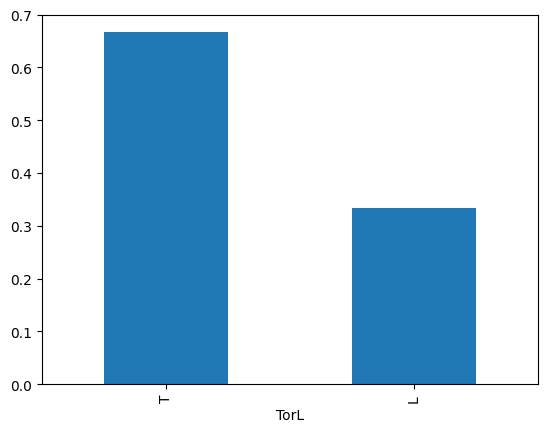

In [ ]:
df["TorL"].value_counts(normalize=True).plot(kind = "bar");


#### Roll the die


In [ ]:
df["roll"] = df["seq"] % 6 + 1
df[:12]

,seq,TorL,roll
0,0,L,1
1,1,L,2
2,2,L,3
3,3,L,4
4,4,L,5
5,5,L,6
6,6,L,1
7,7,L,2
8,8,L,3
9,9,L,4


In [ ]:
df["roll"].value_counts()

,count
roll,
1,150000
2,150000
3,150000
4,150000
5,150000
6,150000


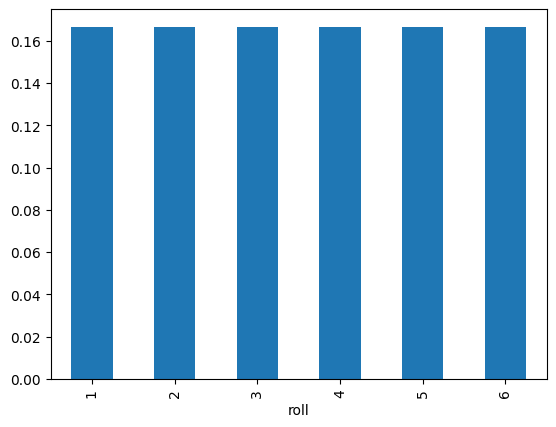

In [ ]:
df["roll"].value_counts(normalize = True).plot(kind="bar") ;

#### What he says - equal distribution

In [ ]:
df["says-eq"] = df["roll"]
lies = ( df["TorL"] == "L" )
df.loc[ lies, "says-eq"] = df[ lies ]["roll"].apply( lambda x: x%6+1)

df[n//3-5:n//3+5]

,seq,TorL,roll,says-eq
299995,299995,L,2,3
299996,299996,L,3,4
299997,299997,L,4,5
299998,299998,L,5,6
299999,299999,L,6,1
300000,300000,T,1,1
300001,300001,T,2,2
300002,300002,T,3,3
300003,300003,T,4,4
300004,300004,T,5,5


In [ ]:
vc = df[["roll","says-eq"]].value_counts().reset_index()
says_3 = ( vc["says-eq"] == 3 )
vc[ says_3 ]


,roll,says-eq,count
3,3,3,100000
6,2,3,50000


In [ ]:
(
  df[["TorL","roll","says-eq"]]
  .value_counts()
  [:,:,3]
  .reset_index()
  .groupby("TorL")
  ["count"]
  .agg("sum")
  .sort_index(ascending = False)
)

,count
TorL,
T,100000
L,50000


#### What he says - lies saying 3

In [ ]:
df["says-3"] = df["roll"]
lies = ( df["TorL"] == "L" )
df.loc[ lies, "says-3"] = df[ lies ]["roll"].apply( lambda x: 4 if x == 3 else 3 )

df[n//3-5:n//3+5]

,seq,TorL,roll,says-eq,says-3
299995,299995,L,2,3,3
299996,299996,L,3,4,4
299997,299997,L,4,5,3
299998,299998,L,5,6,3
299999,299999,L,6,1,3
300000,300000,T,1,1,1
300001,300001,T,2,2,2
300002,300002,T,3,3,3
300003,300003,T,4,4,4
300004,300004,T,5,5,5


In [ ]:
vc = df[["TorL","roll","says-3"]].value_counts().reset_index()
says_3 = ( vc["says-3"] == 3 )
vc[ says_3 ]


,TorL,roll,says-3,count
0,T,3,3,100000
6,L,2,3,50000
7,L,1,3,50000
8,L,4,3,50000
10,L,5,3,50000
11,L,6,3,50000


In [ ]:
(
  df[["TorL","roll","says-3"]]
  .value_counts()
  [:,:,3]
  .reset_index()
  .groupby("TorL")
  ["count"]
  .agg("sum")
  .sort_index(ascending = False)
)

,count
TorL,
T,100000
L,250000


#### What he says - lies saying not 3

In [ ]:
df["says-not_3"] = df["roll"]
lies = ( df["TorL"] == "L" )
df.loc[ lies, "says-not_3"] = df[ lies ]["roll"].apply( lambda x: 2 if x == 4 else 4 )

df[n//3-5:n//3+5]

,seq,TorL,roll,says-eq,says-3,says-not_3
299995,299995,L,2,3,3,4
299996,299996,L,3,4,4,4
299997,299997,L,4,5,3,2
299998,299998,L,5,6,3,4
299999,299999,L,6,1,3,4
300000,300000,T,1,1,1,1
300001,300001,T,2,2,2,2
300002,300002,T,3,3,3,3
300003,300003,T,4,4,4,4
300004,300004,T,5,5,5,5


In [ ]:
vc = df[["roll","says-not_3"]].value_counts().reset_index()
says_3 = ( vc["says-not_3"] == 3 )
vc[ says_3 ]


,roll,says-not_3,count
3,3,3,100000


In [ ]:
(
  df[["TorL","roll","says-not_3"]]
  .value_counts()
  [:,:,3]
  .reset_index()
  .groupby("TorL")
  ["count"]
  .agg("sum")
  .sort_index(ascending = False)
)

,count
TorL,
T,100000
